In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!python.exe -m pip install --upgrade pip
!pip install roboflow
!pip install ultralytics
!pip install -U ipywidgets


/bin/bash: line 1: python.exe: command not found
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 81.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 83.8 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.12.0.88
    Uninstalling opencv-python-headless-4.12.0.88:
      Successfully uninstalled opencv-python-headless-4.12.0.88
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.8/139.8 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [3]:
from ultralytics import YOLO
import torch
import cv2
import matplotlib.pyplot as plt

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [4]:
model = YOLO('yolo11l.pt')

In [5]:
!cp -r /content/drive/MyDrive/Dataset_IOT/LVIS_Fruits_And_Vegetables /content/dataset

In [6]:
results = model.train(data= r'/content/data.yaml', epochs=30, imgsz=640)

Ultralytics 8.3.225 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11l.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.0, pretr

In [7]:
import cv2

#testing 1st image

img_path = "/content/test.jpg"
image = cv2.imread(img_path)
final = model(img_path) #The model is using the weights from your custom-trained model, not the generic pre-trained YOLO model.


image 1/1 /content/test.jpg: 448x640 3 green beans, 10 mushrooms, 2 potatos, 16 tomatos, 59.4ms
Speed: 2.6ms preprocess, 59.4ms inference, 1.4ms postprocess per image at shape (1, 3, 448, 640)


In [8]:
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

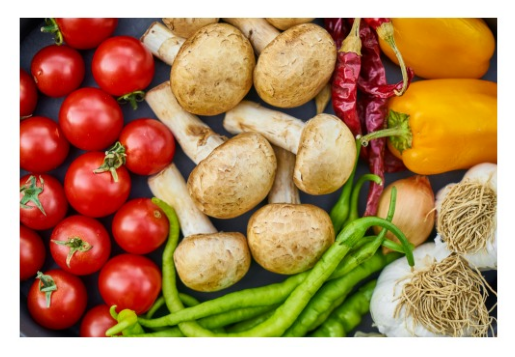

In [9]:
import matplotlib.pyplot as plt
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

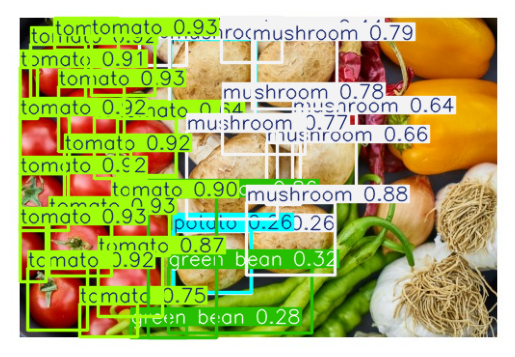

In [14]:
for result in final:
    plt.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))  # plot() draws bounding boxes on the image
    plt.axis("off")
    plt.show()

In [12]:
# Initialize an empty list to store ingredient names
from collections import Counter

ingredient_names = []


for result in final:
    boxes = result.boxes
    classes = result.names

    for box in boxes:
        class_id = int(box.cls.item())
        label = classes[class_id]
        ingredient_names.append(label)

ingredient_counts = Counter(ingredient_names)

formatted_ingredients = [f"{count} {ingredient}" for ingredient, count in ingredient_counts.items()]


print(formatted_ingredients)

['16 tomato', '10 mushroom', '3 green bean', '2 potato']



image 1/1 /content/tomatoes-1296x728-feature.jpg: 384x640 1 orange/orange fruit, 33 tomatos, 31.6ms
Speed: 2.4ms preprocess, 31.6ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)


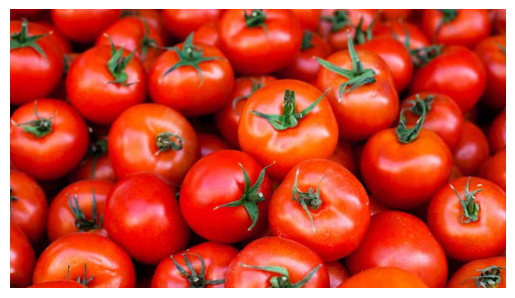

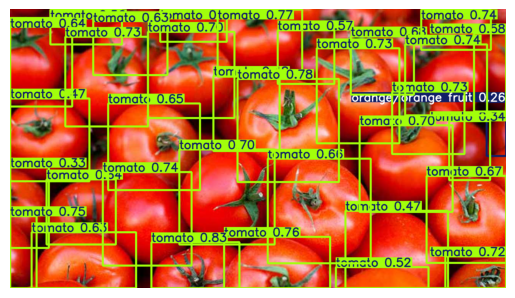

['33 tomato', '1 orange/orange fruit']


In [53]:
import cv2

#testing 1st image
model = YOLO("/content/runs/detect/train/weights/best.pt")

img_path = "/content/tomatoes-1296x728-feature.jpg"
image = cv2.imread(img_path)
final = model(img_path) #The model is using the weights from your custom-trained model, not the generic pre-trained YOLO model.
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
import matplotlib.pyplot as plt
plt.imshow(image_rgb)
plt.axis("off")
plt.show()
for result in final:
    plt.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))  # plot() draws bounding boxes on the image
    plt.axis("off")
    plt.show()
# Initialize an empty list to store ingredient names
from collections import Counter

ingredient_names = []


for result in final:
    boxes = result.boxes
    classes = result.names

    for box in boxes:
        class_id = int(box.cls.item())
        label = classes[class_id]
        ingredient_names.append(label)

ingredient_counts = Counter(ingredient_names)

formatted_ingredients = [f"{count} {ingredient}" for ingredient, count in ingredient_counts.items()]


print(formatted_ingredients)


image 1/1 /content/paryavaraan-broccoli-winter-vegetable-seeds-for-garden-pack-of-30-seeds-product-images-orvjujloc3n-p606513306-0-202312042057.webp: 640x640 2 broccolis, 47.5ms
Speed: 2.6ms preprocess, 47.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


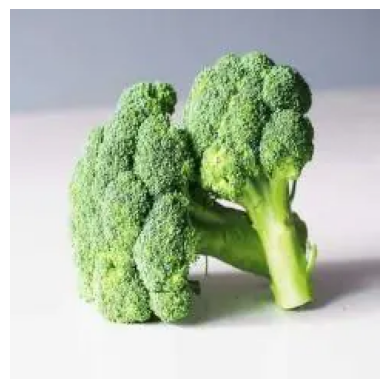

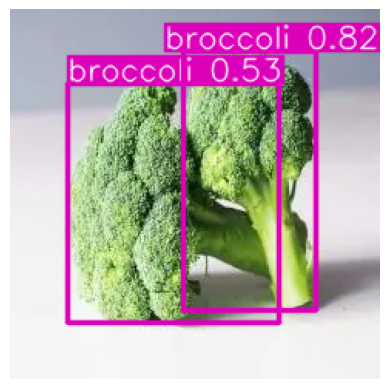

['2 broccoli']


In [56]:
import cv2

#testing 1st image
model = YOLO("/content/runs/detect/train/weights/best.pt")

img_path = "/content/paryavaraan-broccoli-winter-vegetable-seeds-for-garden-pack-of-30-seeds-product-images-orvjujloc3n-p606513306-0-202312042057.webp"
image = cv2.imread(img_path)
final = model(img_path) #The model is using the weights from your custom-trained model, not the generic pre-trained YOLO model.
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
import matplotlib.pyplot as plt
plt.imshow(image_rgb)
plt.axis("off")
plt.show()
for result in final:
    plt.imshow(cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB))  # plot() draws bounding boxes on the image
    plt.axis("off")
    plt.show()
# Initialize an empty list to store ingredient names
from collections import Counter

ingredient_names = []


for result in final:
    boxes = result.boxes
    classes = result.names

    for box in boxes:
        class_id = int(box.cls.item())
        label = classes[class_id]
        ingredient_names.append(label)

ingredient_counts = Counter(ingredient_names)

formatted_ingredients = [f"{count} {ingredient}" for ingredient, count in ingredient_counts.items()]


print(formatted_ingredients)

In [13]:
from google.colab import files

# Path to the best trained model weights
model_path = '/content/runs/detect/train/weights/best.pt'

# Download the file
files.download(model_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>